# 2 · Cointegration diagnostics

For every pair, estimate

$$\log P_{1,t} = \alpha + \beta \log P_{2,t} + \varepsilon_t$$

and test the residual spread for stationarity with the **Engle–Granger** procedure: an ADF test on the residuals, compared against MacKinnon's residual-based critical values (−3.34 at 5% for two variables). Ordinary Dickey–Fuller tables would be wrong here, because the hedge ratio was fitted to make the residuals look as stationary as possible. Then check how the answer changes when

1. the regression direction is reversed,
2. different estimation windows are used,
3. the market enters a high-volatility period, and
4. the two coins are economically linked (same group) rather than unrelated.

Convention throughout: the less liquid coin is the dependent variable (y) and the more liquid coin is the hedge (x). Liquidity order, frozen on median reported spot volume through 31 December 2019: LTC > BCH > TRX > XMR > BNB > ZEC > XLM > LINK. The backtest keeps that direction. It does not choose the regression with the smaller p-value after seeing both tests.

In [1]:
import sys, warnings, itertools
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from cryptopairs import plotting as P
from cryptopairs.project import setup, START
from cryptopairs.data import ORDER
from cryptopairs.dynamic import ordered_pairs
from cryptopairs.stats import ols_hedge, eg_test, half_life
from cryptopairs.risk import EVENTS, high_vol_regime
P.set_style()
pd.set_option("display.precision", 3, "display.width", 170)
px, vol, mkt, sig, risk_off = setup()
lp = np.log(px)
PAIRS = ordered_pairs(ORDER)
GROUP = {"BNB": "platform", "TRX": "platform", "LINK": "oracle", "LTC": "payments", "BCH": "payments",
         "XLM": "payments", "XMR": "privacy", "ZEC": "privacy"}
same = lambda y, x: GROUP[y] == GROUP[x]
print(len(PAIRS), "pairs;", sum(same(y, x) for y, x in PAIRS), "of them within the same economic group:",
      ", ".join(f"{y}~{x}" for y, x in PAIRS if same(y, x)))

28 pairs; 5 of them within the same economic group: BCH~LTC, XLM~LTC, XLM~BCH, BNB~TRX, ZEC~XMR


## 1. Whole test period (2020 – May 2026), both regression directions

In [2]:
def eg(y, x, seg):
    a, b = ols_hedge(seg[y], seg[x])
    s = seg[y] - b * seg[x] - a
    return eg_test(s.to_numpy()).pvalue, b, half_life(s)
seg = lp.loc[START:]
rows = []
for y, x in PAIRS:
    p1, b1, h1 = eg(y, x, seg)
    p2, b2, h2 = eg(x, y, seg)
    rows.append({"pair (y ~ x)": f"{y} ~ {x}", "same group": same(y, x), "p: y on x": p1, "beta: y on x": b1,
                 "half-life (days)": h1, "p: x on y (reversed)": p2})
full = pd.DataFrame(rows).set_index("pair (y ~ x)")
print(f"Cointegrated at 5%: {(full['p: y on x'] < .05).sum()} of {len(full)} (y on x), "
      f"{(full['p: x on y (reversed)'] < .05).sum()} of {len(full)} (reversed); "
      f"expected by chance alone: about {0.05 * len(full):.1f}")
full.sort_values("p: y on x").head(10)

Cointegrated at 5%: 2 of 28 (y on x), 0 of 28 (reversed); expected by chance alone: about 1.4


,same group,p: y on x,beta: y on x,half-life (days),p: x on y (reversed)
pair (y ~ x),,,,,
LINK ~ BCH,False,0.028,0.754,103.237,0.158
LINK ~ XLM,False,0.029,0.819,75.795,0.094
LINK ~ LTC,False,0.057,1.107,97.105,0.149
XMR ~ TRX,False,0.092,0.461,71.181,0.294
XLM ~ LTC,True,0.143,1.157,108.426,0.114
XLM ~ BCH,True,0.149,0.782,143.994,0.298
LINK ~ ZEC,False,0.157,0.245,144.218,0.973
LINK ~ BNB,False,0.232,0.280,134.082,0.850
XLM ~ XMR,False,0.235,0.963,121.085,0.356


Over the whole 6.4-year period no pair passes at 5% with the less liquid coin as y, and only 2 of 28 pass in the reversed direction, close to the 1.4 false positives expected by chance from 28 tests. The implied half-lives of the best candidates (70–185 days) are far too slow to trade. A pairs trader therefore has to rely on **local** cointegration: relationships that hold for a few months and are re-tested continuously. The static strategy does this with 365-day windows and the dynamic strategy with 180-day windows.

## 2. Different estimation windows

Rolling Engle–Granger tests with windows of 180, 365 and 730 days, moved forward 30 days at a time, with windows ending between Jan 2020 and May 2026. If no pair were ever cointegrated, about 5% of windows would pass by chance with one fixed direction, and somewhat more (about 8–9%) when the better of the two directions is kept.

In [3]:
ends = lp.loc[START:].index[::30]
recs = []
for L in [180, 365, 730]:
    for y, x in PAIRS:
        for d in ends:
            w = lp.loc[d - pd.Timedelta(days=L - 1):d]
            if w[[y, x]].isna().any().any():
                continue
            p_yx, b_yx, hl = eg(y, x, w)
            p_xy, _, _ = eg(x, y, w)
            recs.append({"window": L, "pair": f"{y} ~ {x}", "same group": same(y, x), "end": d,
                         "p_yx": p_yx, "p_xy": p_xy, "beta": b_yx, "half_life": hl})
roll = pd.DataFrame(recs)
roll["sig_yx"], roll["sig_xy"] = roll.p_yx < .05, roll.p_xy < .05
roll["either"], roll["disagree"] = roll.sig_yx | roll.sig_xy, roll.sig_yx ^ roll.sig_xy
summ = roll.groupby("window").agg(**{
    "windows tested": ("sig_yx", "size"),
    "share passing (y on x)": ("sig_yx", "mean"),
    "share passing (reversed)": ("sig_xy", "mean"),
    "share passing (either)": ("either", "mean"),
    "directions disagree": ("disagree", "mean"),
    "median beta": ("beta", "median")})
summ

,windows tested,share passing (y on x),share passing (reversed),share passing (either),directions disagree,median beta
window,,,,,,
180,2184,0.091,0.116,0.154,0.102,0.694
365,2184,0.086,0.073,0.113,0.067,0.703
730,2142,0.092,0.124,0.170,0.126,0.765


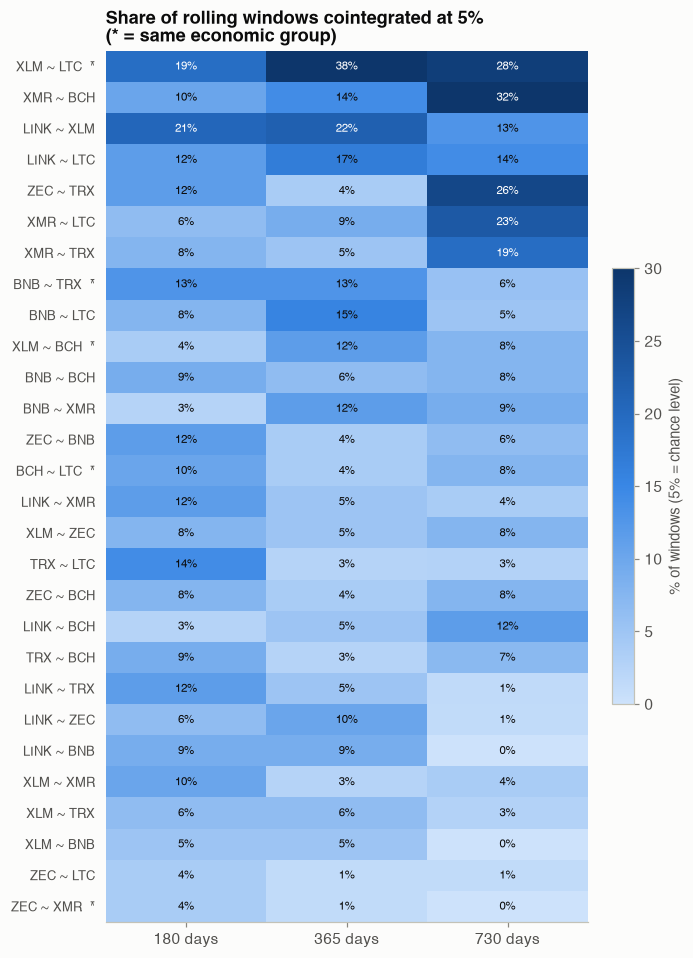

In [4]:
heat = roll.pivot_table(index="pair", columns="window", values="sig_yx", aggfunc="mean")
heat = heat.loc[heat.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(6.2, 8.6))
from matplotlib.colors import LinearSegmentedColormap
im = ax.imshow(heat.to_numpy() * 100, cmap=LinearSegmentedColormap.from_list("s", P.SEQ), vmin=0, vmax=30, aspect="auto")
ax.set_xticks(range(3), [f"{c} days" for c in heat.columns])
labels = [f"{p}  *" if same(*p.split(" ~ ")) else p for p in heat.index]
ax.set_yticks(range(len(heat)), labels, fontsize=8.5)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.iloc[i, j] * 100
        ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=7.5, color=P.INK if v < 18 else "white")
ax.grid(False); ax.set_title("Share of rolling windows cointegrated at 5%\n(* = same economic group)")
fig.colorbar(im, ax=ax, shrink=0.5, label="% of windows (5% = chance level)")
P.save(fig, "02_rolling_share")

Pass rates are only modestly above chance. With the fixed direction, about 9% of the 180-day, 365-day and 730-day windows pass, against 5% if no pair were ever cointegrated. The **regression direction matters**: the two directions disagree on about 7% to 13% of windows, so a strategy that tries both and keeps the better p-value is quietly running extra tests. Some pairs pass far more often than others, but no pair passes in most of its windows. Overlapping windows share most of their days, so the pass rate is not a set of independent tests. A 5% line is the size of one test, not the expected share of a path of overlapping windows.

## 3. Economic links: do coins from the same group pair better?

In [5]:
grp = roll.groupby(["window", "same group"]).agg(**{"pair-windows": ("sig_yx", "size"),
                                                   "share cointegrated": ("sig_yx", "mean"),
                                                   "median half-life (days)": ("half_life", lambda s: s.replace(np.inf, np.nan).median())}).unstack("same group")
grp

pair-windows       share cointegrated        median half-life (days)        
same group        False True               False  True                    False   True 
window                                                                                 
180                1794   390              0.089  0.100                  13.587  11.480
365                1794   390              0.075  0.136                  25.480  24.185
730                1758   384              0.090  0.099                  55.172  49.772

Economic links help only a little. Same-group pairs pass more often on 365-day windows (14% against 8%) and about as often on 180-day windows (10% against 9%) and on 730-day windows (10% against 9%). Half-lives are similar. Belonging to the same sector is not a substitute for the test.

## 4. Does cointegration survive high volatility?

Split the 180-day windows by the market regime on their last day: is a pair as likely to look cointegrated, and is its hedge ratio as stable, when the market is in its high-volatility regime?

In [6]:
hv = high_vol_regime(mkt)
r180 = roll[roll.window == 180].copy()
r180["high_vol_now"] = hv.reindex(r180.end).to_numpy()
r180 = r180.sort_values(["pair", "end"])
r180["beta_change_30d"] = r180.groupby("pair").beta.diff().abs()
out = r180.groupby("high_vol_now").agg(**{
    "windows": ("sig_yx", "size"), "share cointegrated": ("sig_yx", "mean"),
    "median half-life (days)": ("half_life", lambda s: s.replace(np.inf, np.nan).median()),
    "median |change in beta| over 30 days": ("beta_change_30d", "median")})
out.index = out.index.map({False: "normal", True: "high volatility"})
out

,windows,share cointegrated,median half-life (days),median |change in beta| over 30 days
high_vol_now,,,,
normal,1960,0.088,13.487,0.166
high volatility,224,0.116,12.008,0.131


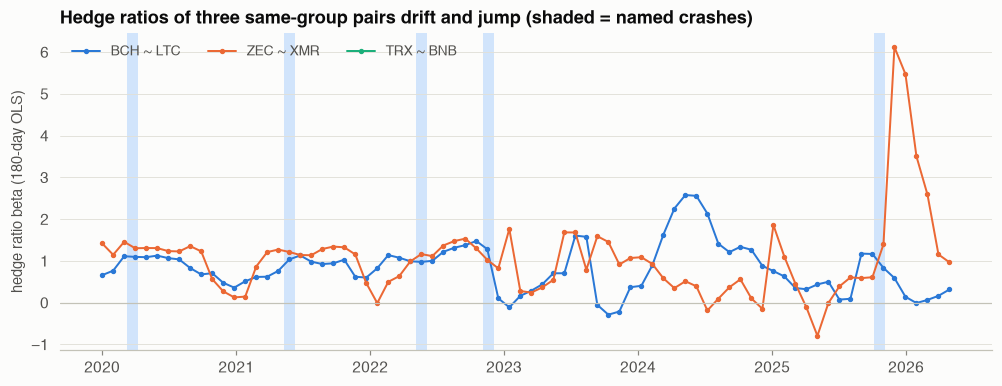

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.4))
show = ["BCH ~ LTC", "ZEC ~ XMR", "TRX ~ BNB"]
for i, p in enumerate(show):
    b = r180[r180.pair == p].set_index("end").beta
    ax.plot(b.index, b, color=P.C[i], label=p, marker="o", ms=2.5, lw=1.3)
for name, (a, b_) in EVENTS.items():
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b_), color=P.SEQ[0], alpha=0.9, lw=0, zorder=0)
ax.axhline(0, color=P.AXIS, lw=0.8)
ax.set_ylabel("hedge ratio beta (180-day OLS)")
ax.set_title("Hedge ratios of three same-group pairs drift and jump (shaded = named crashes)")
ax.legend(loc="upper left", ncols=3)
P.save(fig, "02_rolling_beta")

## Takeaways for the strategy design

* **No full-sample relationship we would trade.** Over 2020–2026 the traded direction does not reject at 5% much more often than the size of the test. That is a failure to detect cointegration on this sample, not a proof that no pair is cointegrated. A strategy has to re-estimate and re-test as it goes.
* **Local cointegration is weak.** Rolling windows pass only modestly more often than chance (7–13% vs 5%), so a cointegration gate will keep a strategy out of the market most of the time.
* **Economic links are not a shortcut.** Same-group pairs (payments, privacy, platforms) are not consistently more cointegrated than unrelated ones.
* **Direction matters.** We fix the direction by liquidity (less liquid on more liquid) instead of picking whichever direction gives the better p-value, and test the alternative in notebook 6.
* **The test gives no early warning of crashes.** Windows ending in the high-volatility regime pass slightly more often (about 12% against 9%), with similar half-lives, and hedge ratios move no more than usual. The danger is not visible in the test; it shows up in what spreads do after entry. Notebooks 3–5 measure that.